# FitPredict
## Machine Learning-Based Calorie Expenditure Prediction System

### Objective
To develop a supervised machine learning regression model
that predicts calorie expenditure using exercise-related
and physiological measurements.



In [1]:
import sys

print("Python version:", sys.version)
print("Python executable:", sys.executable)

Python version: 3.11.3 (tags/v3.11.3:f3909b8, Apr  4 2023, 23:49:59) [MSC v.1934 64 bit (AMD64)]
Python executable: C:\Users\user\AppData\Local\Programs\Python\Python311\python.exe


In [3]:
import pandas as pd
import numpy as np
import sklearn
import matplotlib.pyplot as plt 
import seaborn as sns
from datasets import load_dataset

In [4]:
exercise=pd.read_csv( "https://huggingface.co/datasets/mnemoraorg/calorie-burnt-15k/resolve/main/raw_exercise.csv")
calories=pd.read_csv( "https://huggingface.co/datasets/mnemoraorg/calorie-burnt-15k/resolve/main/raw_calories.csv")


### Inspecting the two datasets

In [5]:
display(exercise.head())

,User_ID,Gender,Age,Height,Weight,Duration,Heart_Rate,Body_Temp
0,14733363,male,68,190.0,94.0,29.0,105.0,40.8
1,14861698,female,20,166.0,60.0,14.0,94.0,40.3
2,11179863,male,69,179.0,79.0,5.0,88.0,38.7
3,16180408,female,34,179.0,71.0,13.0,100.0,40.5
4,17771927,female,27,154.0,58.0,10.0,81.0,39.8


In [6]:
display(calories.head())

,User_ID,Calories
0,14733363,231.0
1,14861698,66.0
2,11179863,26.0
3,16180408,71.0
4,17771927,35.0


In [7]:
print("Exercise shape:",exercise.shape)

Exercise shape: (15000, 8)


In [8]:
print("Calories shape:",calories.shape)

Calories shape: (15000, 2)


### Merging the dataset using User_ID

In [9]:
df=pd.merge(exercise,calories,on="User_ID",how="inner",validate="one_to_one")

### Inspecting

In [10]:
display(df.head())

,User_ID,Gender,Age,Height,Weight,Duration,Heart_Rate,Body_Temp,Calories
0,14733363,male,68,190.0,94.0,29.0,105.0,40.8,231.0
1,14861698,female,20,166.0,60.0,14.0,94.0,40.3,66.0
2,11179863,male,69,179.0,79.0,5.0,88.0,38.7,26.0
3,16180408,female,34,179.0,71.0,13.0,100.0,40.5,71.0
4,17771927,female,27,154.0,58.0,10.0,81.0,39.8,35.0


In [11]:
print("Merged dataset shape:",df.shape)

Merged dataset shape: (15000, 9)


In [12]:
print(df.columns)

Index(['User_ID', 'Gender', 'Age', 'Height', 'Weight', 'Duration',
       'Heart_Rate', 'Body_Temp', 'Calories'],
      dtype='str')


In [13]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   User_ID     15000 non-null  int64  
 1   Gender      15000 non-null  str    
 2   Age         15000 non-null  int64  
 3   Height      15000 non-null  float64
 4   Weight      15000 non-null  float64
 5   Duration    15000 non-null  float64
 6   Heart_Rate  15000 non-null  float64
 7   Body_Temp   15000 non-null  float64
 8   Calories    15000 non-null  float64
dtypes: float64(6), int64(2), str(1)
memory usage: 1.1 MB


In [14]:
print(df.isnull().sum())

User_ID       0
Gender        0
Age           0
Height        0
Weight        0
Duration      0
Heart_Rate    0
Body_Temp     0
Calories      0
dtype: int64


In [15]:
print(df.duplicated().sum())

0


In [16]:
print("Duplicate User IDs:",df["User_ID"].duplicated().sum())

Duplicate User IDs: 0


In [17]:
print(df["Gender"].unique())

<ArrowStringArray>
['male', 'female']
Length: 2, dtype: str


In [18]:
print(df["Gender"].value_counts())

Gender
female    7553
male      7447
Name: count, dtype: int64


In [19]:
df.describe()

,User_ID,Age,Height,Weight,Duration,Heart_Rate,Body_Temp,Calories
count,1.500000e+04,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000
mean,1.497736e+07,42.789800,174.465133,74.966867,15.530600,95.518533,40.025453,89.539533
std,2.872851e+06,16.980264,14.258114,15.035657,8.319203,9.583328,0.779230,62.456978
min,1.000116e+07,20.000000,123.000000,36.000000,1.000000,67.000000,37.100000,1.000000
25%,1.247419e+07,28.000000,164.000000,63.000000,8.000000,88.000000,39.600000,35.000000
50%,1.499728e+07,39.000000,175.000000,74.000000,16.000000,96.000000,40.200000,79.000000
75%,1.744928e+07,56.000000,185.000000,87.000000,23.000000,103.000000,40.600000,138.000000
max,1.999965e+07,79.000000,222.000000,132.000000,30.000000,128.000000,41.500000,314.000000


In [20]:
columns=[ 'Age', 'Height', 'Weight', 'Duration',
       'Heart_Rate', 'Body_Temp', 'Calories']

for column in columns:
    print(column,"Minimum:",df[column].min(),"Maximum:",df[column].max())

Age Minimum: 20 Maximum: 79
Height Minimum: 123.0 Maximum: 222.0
Weight Minimum: 36.0 Maximum: 132.0
Duration Minimum: 1.0 Maximum: 30.0
Heart_Rate Minimum: 67.0 Maximum: 128.0
Body_Temp Minimum: 37.1 Maximum: 41.5
Calories Minimum: 1.0 Maximum: 314.0


### Identifying potential outliers

In [21]:
for column in columns:
    Q1=df[column].quantile(0.25)
    Q3=df[column].quantile(0.75)
    IQR=Q3-Q1

    lower_limit=Q1-1.5*IQR
    upper_limit=Q3+1.5*IQR

    outliers=df[(df[column]<lower_limit)|(df[column]>upper_limit)]

    print(column,"Potential outliers:",len(outliers))

Age Potential outliers: 0
Height Potential outliers: 14
Weight Potential outliers: 6
Duration Potential outliers: 0
Heart_Rate Potential outliers: 1
Body_Temp Potential outliers: 369
Calories Potential outliers: 4


### Investigating the Outlier 

In [22]:
for column in columns:
    Q1=df[column].quantile(0.25)
    Q3=df[column].quantile(0.75)
    IQR=Q3-Q1

    lower_limit=Q1-1.5*IQR
    upper_limit=Q3+1.5*IQR

    outliers=df[(df[column]<lower_limit)|(df[column]>upper_limit)]

    print("\nFeature:", column)
    print("Lower limit:", lower_limit)
    print("Upper limit:", upper_limit)
    print("Outlier count:", len(outliers))

    display(outliers[[column]].head(10))
 


Feature: Age
Lower limit: -14.0
Upper limit: 98.0
Outlier count: 0


,Age



Feature: Height
Lower limit: 132.5
Upper limit: 216.5
Outlier count: 14


,Height
529,132.0
1464,217.0
4200,123.0
4404,132.0
4855,132.0
6226,127.0
6711,218.0
7774,126.0
8931,132.0
10362,222.0



Feature: Weight
Lower limit: 27.0
Upper limit: 123.0
Outlier count: 6


,Weight
1909,124.0
6711,132.0
10362,128.0
12189,126.0
13276,126.0
13806,124.0


... (4 outputs left out)


Feature: Body_Temp
Lower limit: 38.1
Upper limit: 42.1
Outlier count: 369


,Body_Temp
10,37.8
24,37.7
49,38.0
232,37.9
301,37.6
317,37.9
403,37.7
442,37.9
462,37.9
499,37.8



Feature: Calories
Lower limit: -119.5
Upper limit: 292.5
Outlier count: 4


,Calories
428,314.0
3357,295.0
6240,300.0
13871,295.0


##### Checking zero and negative values

In [23]:
for column in columns:

    print("\n", column)

    print("Zero values:", (df[column] == 0).sum())

    print("Negative values:", (df[column] < 0).sum())


 Age
Zero values: 0
Negative values: 0

 Height
Zero values: 0
Negative values: 0

 Weight
Zero values: 0
Negative values: 0

 Duration
Zero values: 0
Negative values: 0

 Heart_Rate
Zero values: 0
Negative values: 0

 Body_Temp
Zero values: 0
Negative values: 0

 Calories
Zero values: 0
Negative values: 0


In [24]:
df_clean=df.copy()
print("Shape:",df_clean.shape)

Shape: (15000, 9)


In [25]:
import os

print("Current location:")
print(os.getcwd())

print("\nFolders in parent directory:")
print(os.listdir(".."))

Current location:
C:\Users\user\OneDrive\Desktop\FitPredict\Notebooks

Folders in parent directory:
['.git', '.gitignore', 'Data', 'Models', 'Notebooks', 'Processed', 'Raw', 'Reports']


In [26]:
df_clean.to_csv(
    "../Processed/fitpredict_validated.csv",
    index=False
)

print("Validated dataset saved successfully!")

Validated dataset saved successfully!


In [27]:
import os

file_path = "../Processed/fitpredict_validated.csv"

print("File exists:", os.path.exists(file_path))

File exists: True


### EDA 

In [28]:
num_columns=['Age', 'Height', 'Weight', 'Duration',
       'Heart_Rate', 'Body_Temp', 'Calories']
catg_columns=['Gender']

#### Univariate Analysis

In [29]:
df_clean[num_columns].describe()

,Age,Height,Weight,Duration,Heart_Rate,Body_Temp,Calories
count,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000
mean,42.789800,174.465133,74.966867,15.530600,95.518533,40.025453,89.539533
std,16.980264,14.258114,15.035657,8.319203,9.583328,0.779230,62.456978
min,20.000000,123.000000,36.000000,1.000000,67.000000,37.100000,1.000000
25%,28.000000,164.000000,63.000000,8.000000,88.000000,39.600000,35.000000
50%,39.000000,175.000000,74.000000,16.000000,96.000000,40.200000,79.000000
75%,56.000000,185.000000,87.000000,23.000000,103.000000,40.600000,138.000000
max,79.000000,222.000000,132.000000,30.000000,128.000000,41.500000,314.000000


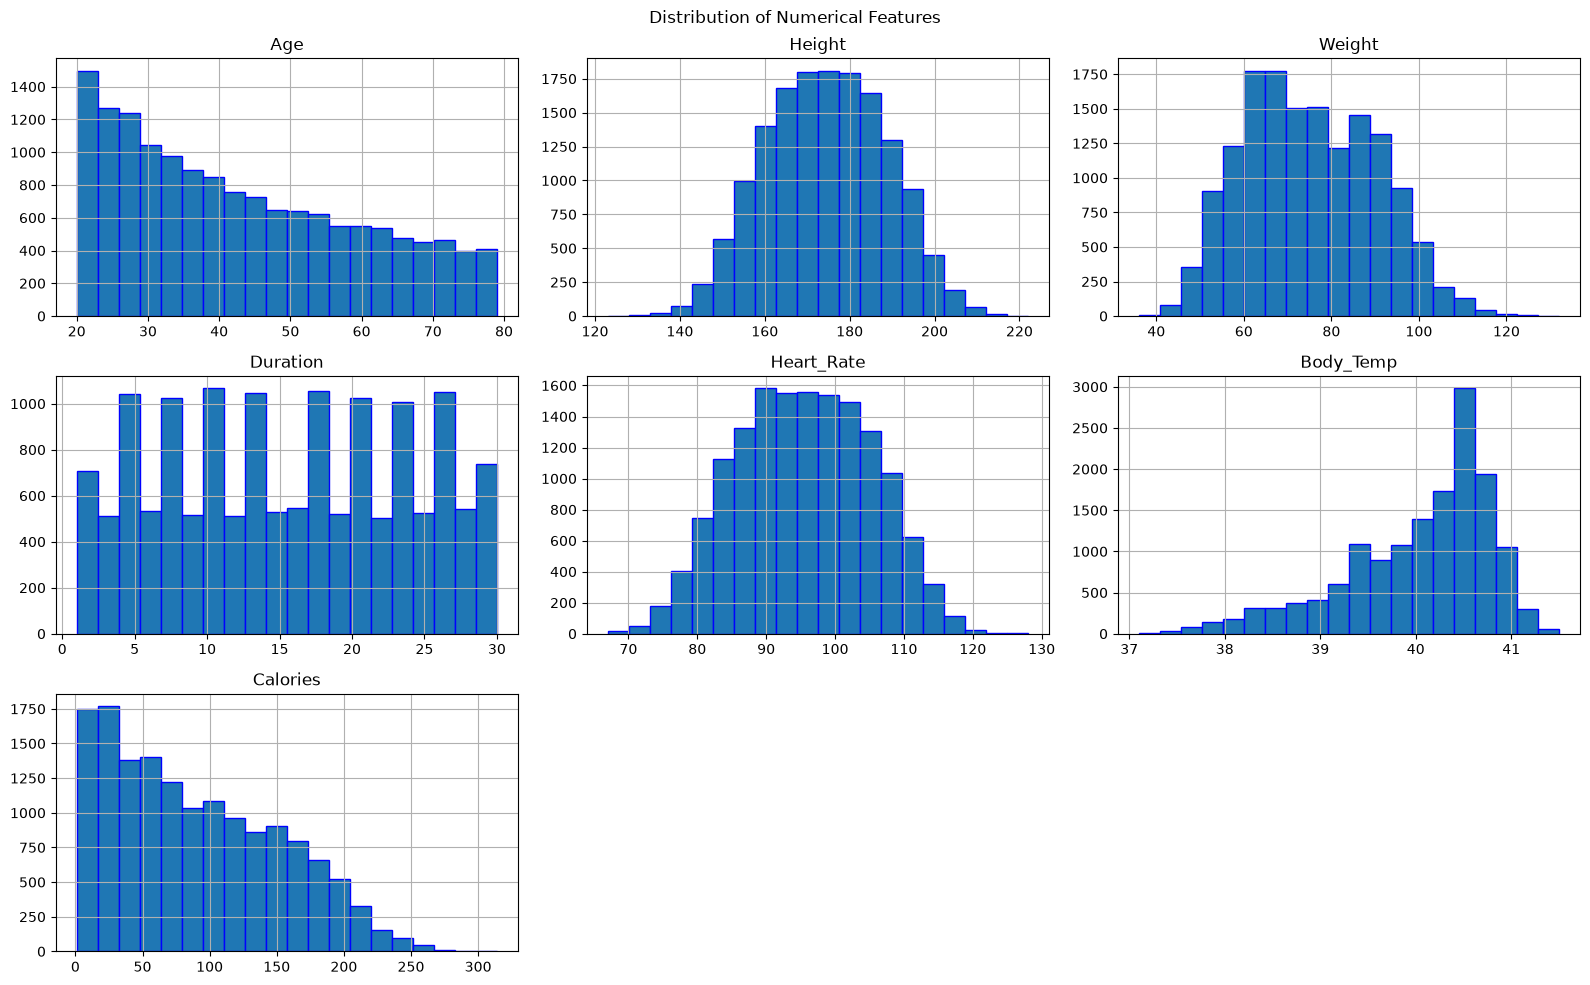

In [30]:
df_clean[num_columns].hist(figsize=(16,10),bins=20,edgecolor="blue")
plt.suptitle("Distribution of Numerical Features")
plt.tight_layout()
plt.show()

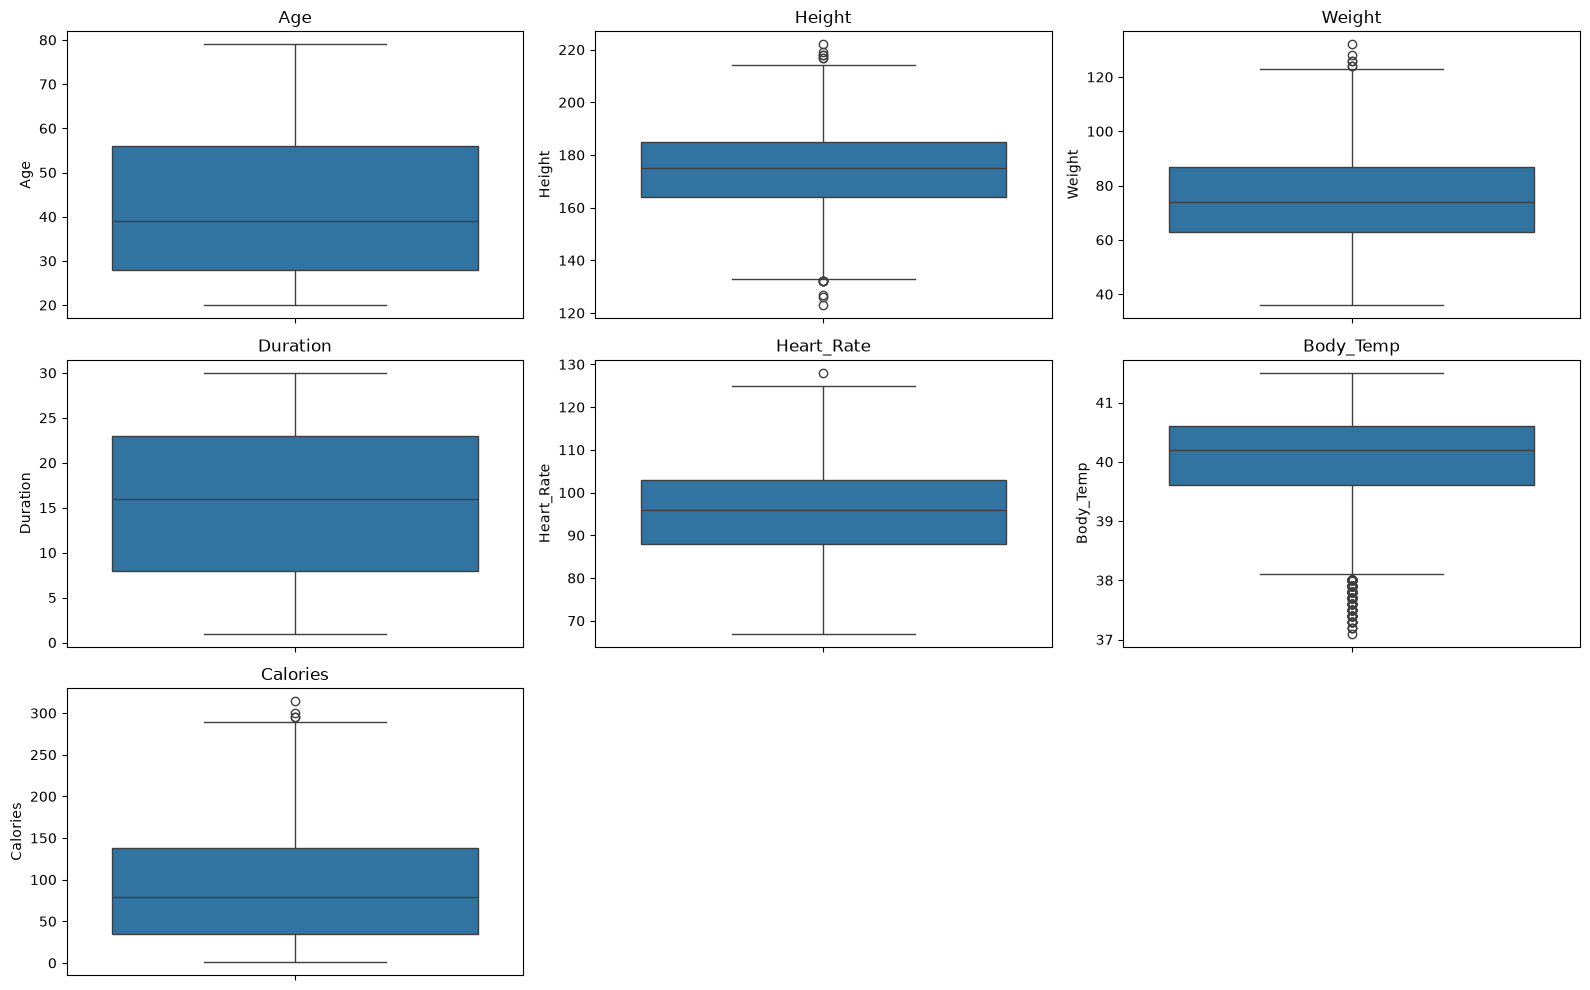

In [31]:
plt.figure(figsize=(16,10))
for i,column in enumerate(num_columns,1):
    plt.subplot(3,3,i)
    sns.boxplot(y=df_clean[column])
    plt.title(column)

plt.tight_layout()
plt.show()

### Univariate Analysis-Categorical

In [32]:
print(df_clean["Gender"].value_counts())
print(df_clean["Gender"].value_counts(normalize=True)*100)
    

Gender
female    7553
male      7447
Name: count, dtype: int64
Gender
female    50.353333
male      49.646667
Name: proportion, dtype: float64


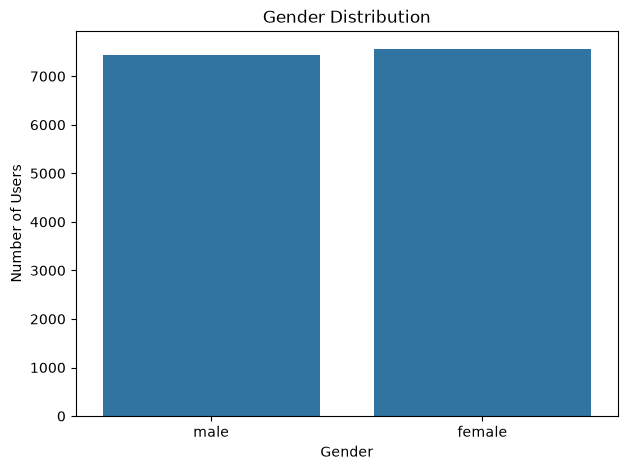

In [33]:
plt.figure(figsize=(7,5))
sns.countplot(data=df_clean,x="Gender")
plt.title("Gender Distribution")
plt.xlabel("Gender")
plt.ylabel("Number of Users")
plt.show()

### Bivariate Analysis

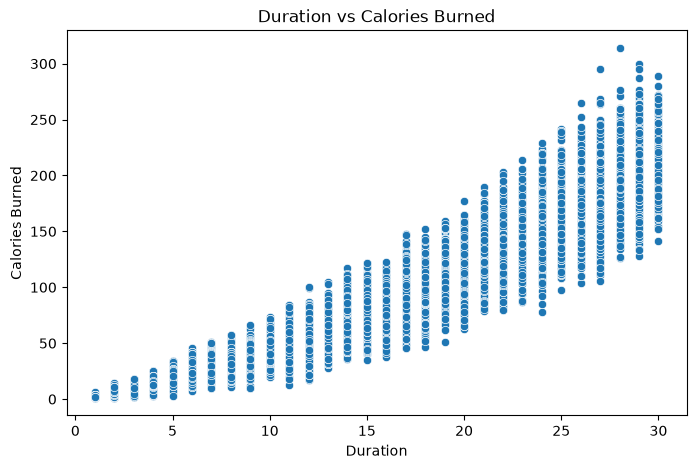

In [34]:
plt.figure(figsize=(8,5))
sns.scatterplot(data=df_clean,x="Duration",y="Calories")
plt.title("Duration vs Calories Burned")
plt.xlabel("Duration")
plt.ylabel("Calories Burned")
plt.show()

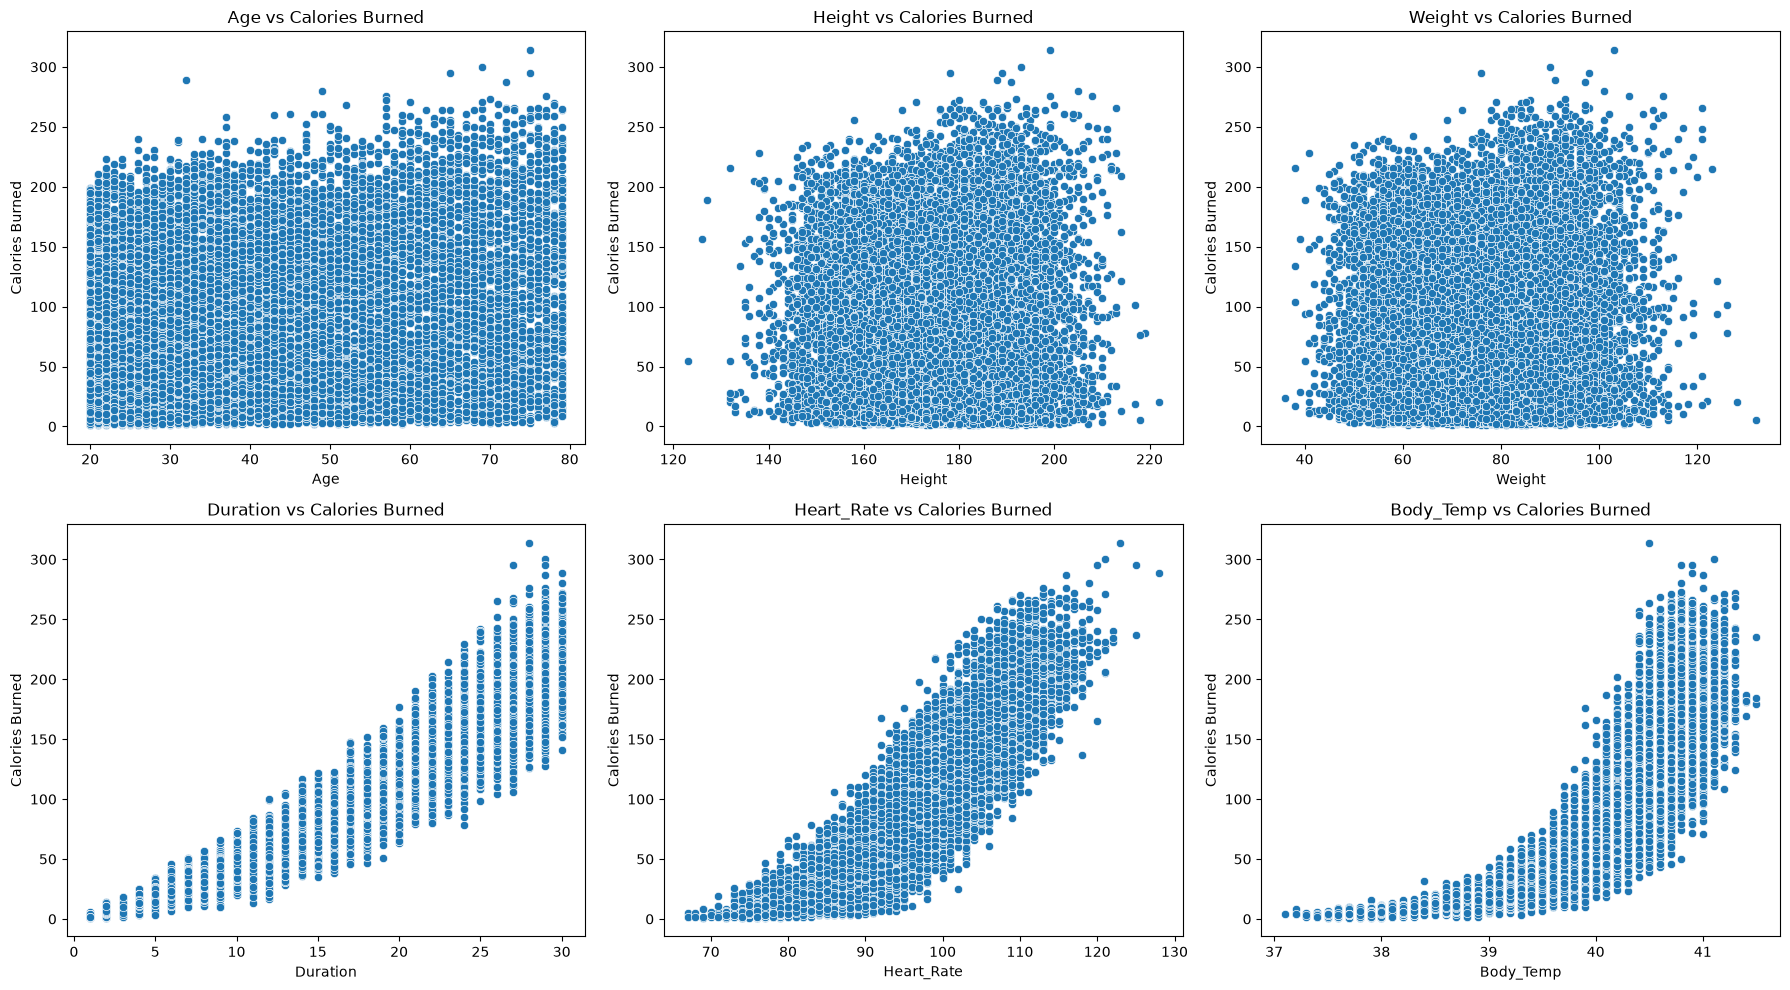

In [41]:
features = ['Age', 'Height', 'Weight', 'Duration',
       'Heart_Rate', 'Body_Temp']
   
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, feature in enumerate(features):
    sns.scatterplot(data=df_clean,x=feature,y="Calories",ax=axes[i])
    axes[i].set_title(f"{feature} vs Calories Burned")
    axes[i].set_xlabel(feature)
    axes[i].set_ylabel("Calories Burned")

plt.tight_layout()
plt.show()


In [43]:
gender_calories=df_clean.groupby("Gender")["Calories"].mean()
print(gender_calories)

Gender
female    88.153052
male      90.945750
Name: Calories, dtype: float64


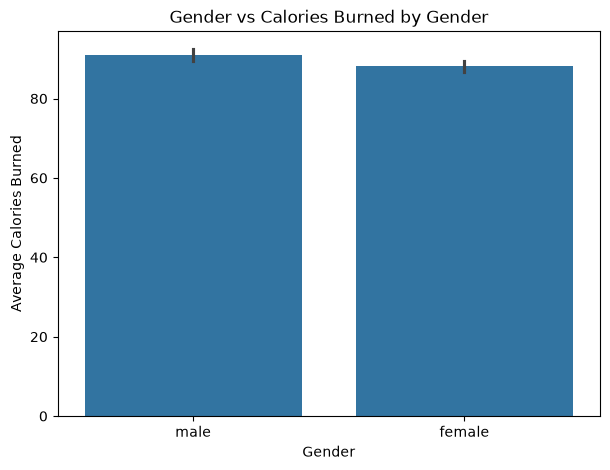

In [44]:
plt.figure(figsize=(7,5))
sns.barplot(data=df_clean,x="Gender",y="Calories")
plt.title("Gender vs Calories Burned by Gender")
plt.xlabel("Gender")
plt.ylabel("Average Calories Burned")
plt.show()

### Correlation Analysis

                 Age    Height    Weight  Duration  Heart_Rate  Body_Temp  \
Age         1.000000  0.009554  0.090094  0.013247    0.010482   0.013175   
Height      0.009554  1.000000  0.958451 -0.004625    0.000528   0.001200   
Weight      0.090094  0.958451  1.000000 -0.001884    0.004311   0.004095   
Duration    0.013247 -0.004625 -0.001884  1.000000    0.852869   0.903167   
Heart_Rate  0.010482  0.000528  0.004311  0.852869    1.000000   0.771529   
Body_Temp   0.013175  0.001200  0.004095  0.903167    0.771529   1.000000   
Calories    0.154395  0.017537  0.035481  0.955421    0.897882   0.824558   

            Calories  
Age         0.154395  
Height      0.017537  
Weight      0.035481  
Duration    0.955421  
Heart_Rate  0.897882  
Body_Temp   0.824558  
Calories    1.000000  


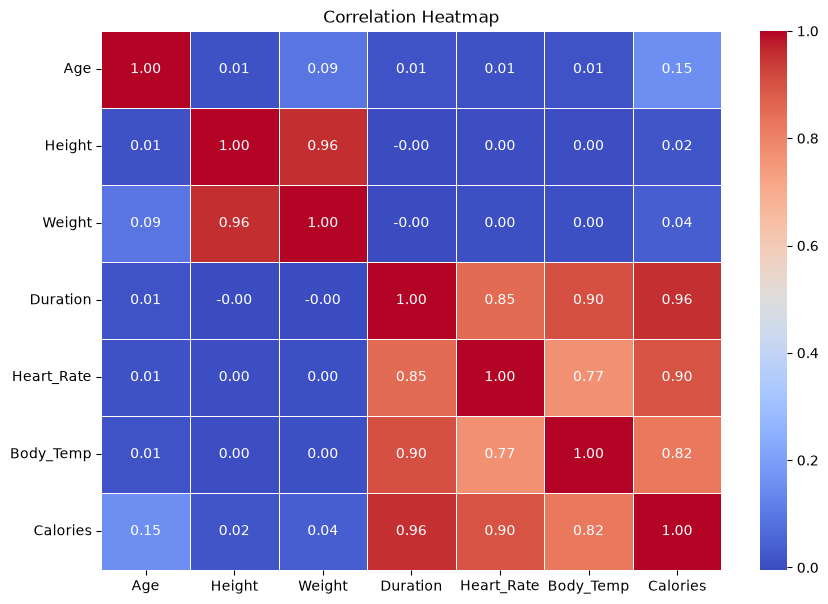

In [46]:
correlation=df_clean[num_columns].corr()
print(correlation)

plt.figure(figsize=(10,7))
sns.heatmap(correlation,annot=True,cmap="coolwarm",fmt=".2f",linewidth=0.5)

plt.title("Correlation Heatmap")
plt.show()

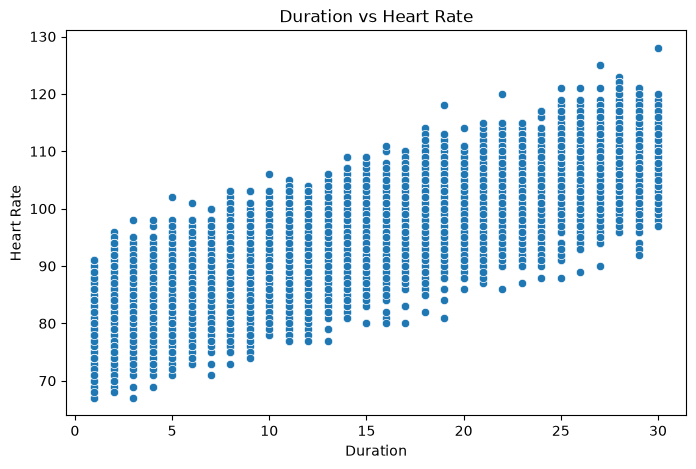

In [48]:
plt.figure(figsize=(8,5))
sns.scatterplot(data=df_clean,x="Duration",y="Heart_Rate")
plt.title("Duration vs Heart Rate")
plt.xlabel("Duration")
plt.ylabel("Heart Rate")
plt.show()

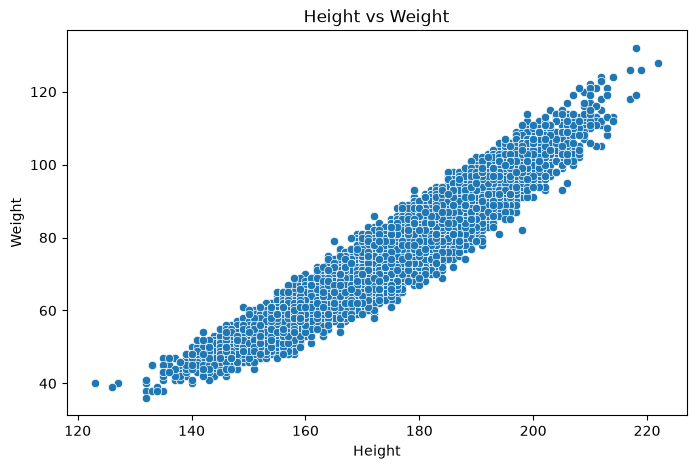

In [49]:
plt.figure(figsize=(8,5))
sns.scatterplot(data=df_clean,x="Height",y="Weight")
plt.title("Height vs Weight")
plt.xlabel("Height")
plt.ylabel("Weight")
plt.show()

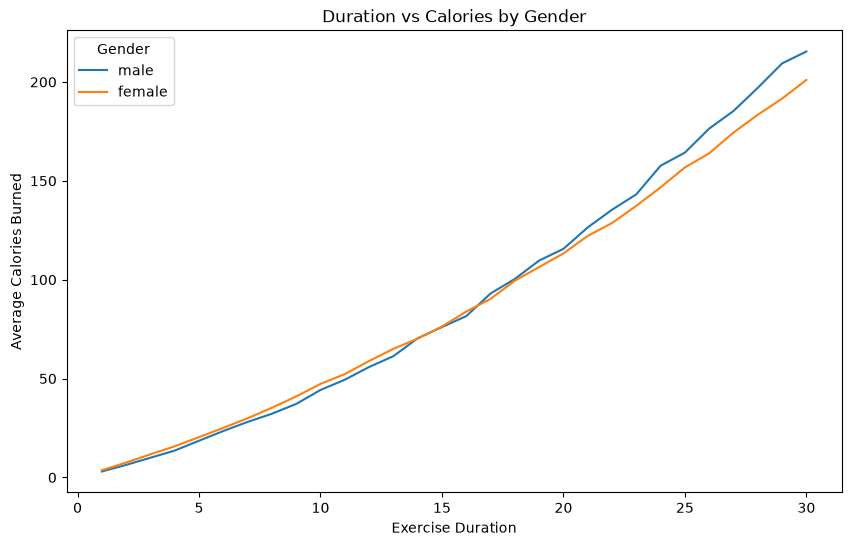

In [50]:
plt.figure(figsize=(10,6))
sns.lineplot(data=df_clean,x="Duration",y="Calories",hue="Gender",errorbar=None)
plt.title("Duration vs Calories by Gender")
plt.xlabel("Exercise Duration")
plt.ylabel("Average Calories Burned")
plt.show()

<function matplotlib.pyplot.show(close=None, block=None)>

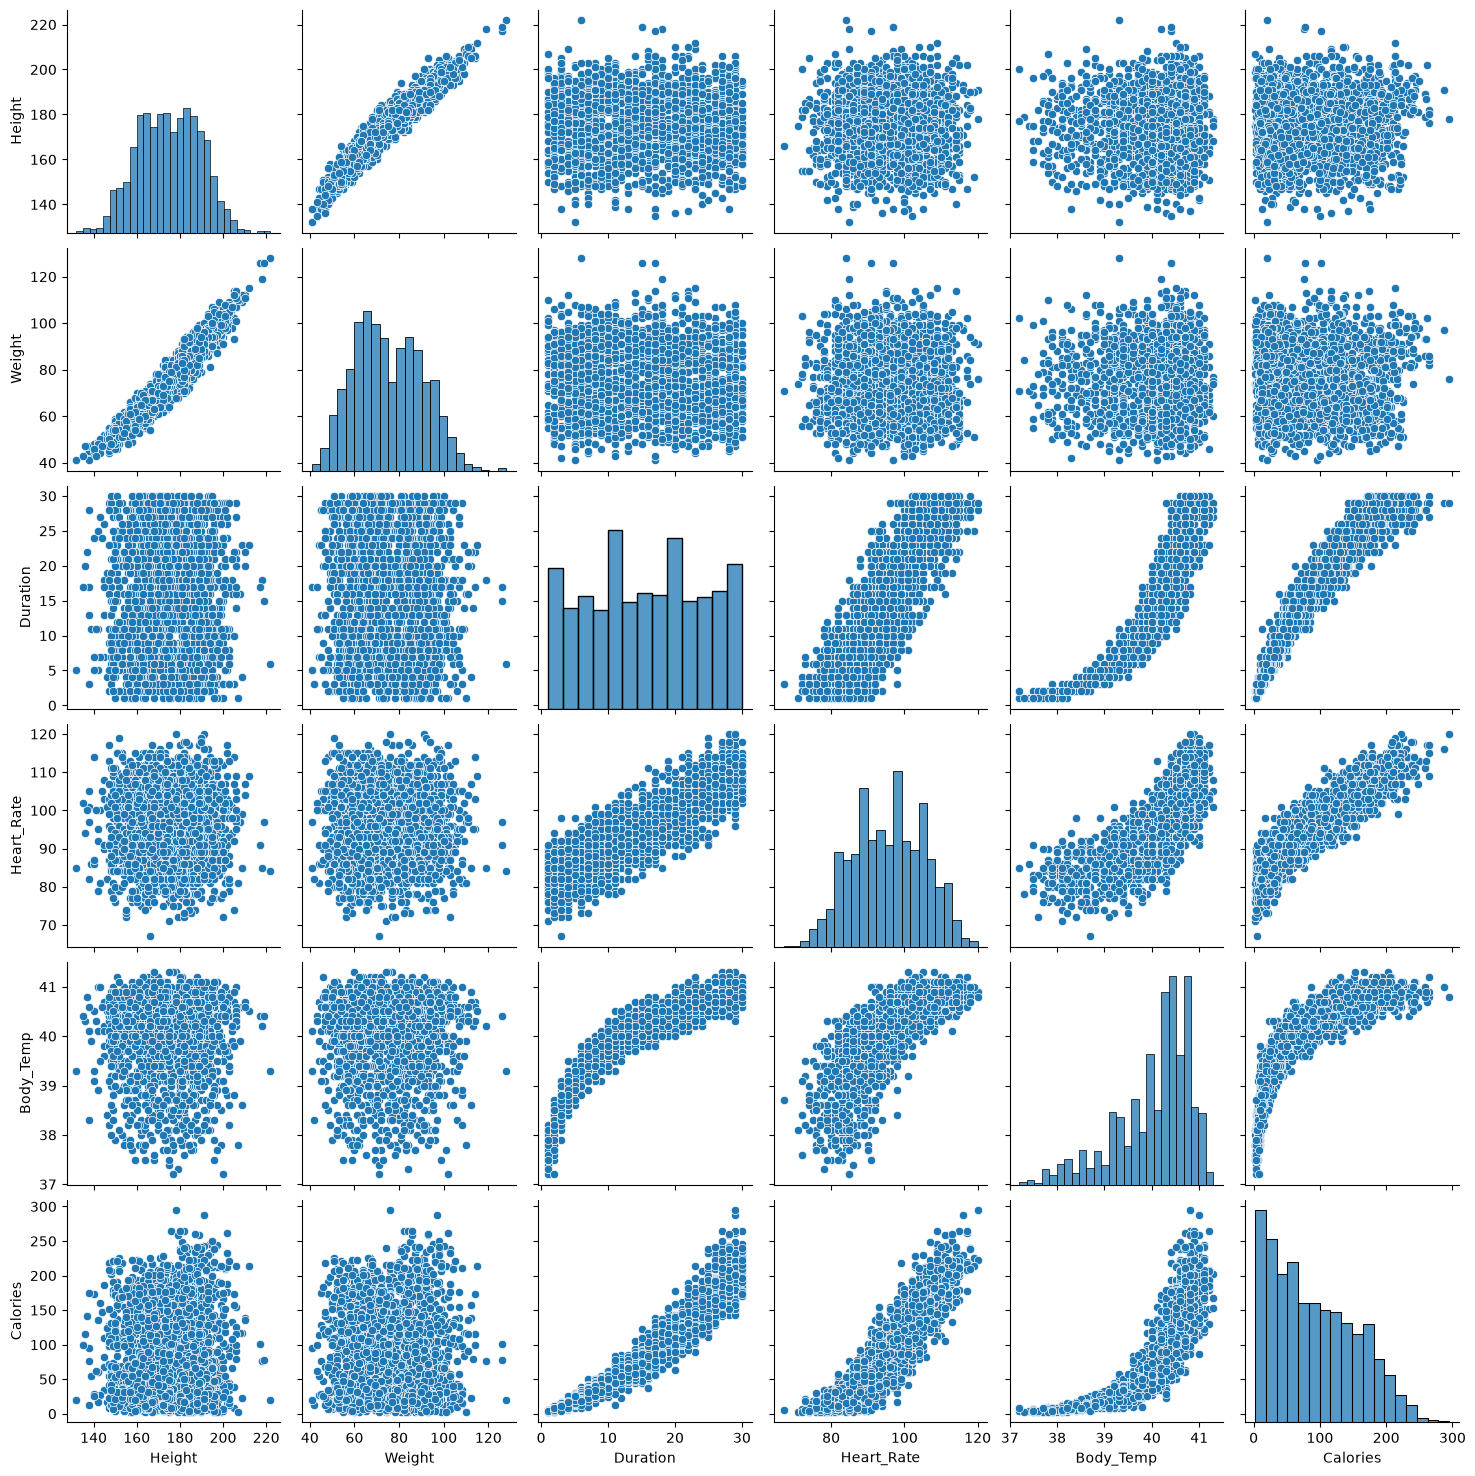

In [53]:
pairplot_columns=['Height', 'Weight', 'Duration',
       'Heart_Rate', 'Body_Temp','Calories']


sample_df=df_clean.sample(n=2000,random_state=42)
sns.pairplot(sample_df[pairplot_columns],diag_kind="hist")

plt.show